### Exploración de datos 

Definimos las clases y obtenemos los datos.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path("data")
TRAIN_DIR = ROOT / "train"
TEST_DIR = ROOT / "test"

CLASSES = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

assert TRAIN_DIR.exists(), f"No existe: {TRAIN_DIR.resolve()}"
assert TEST_DIR.exists(), f"No existe: {TEST_DIR.resolve()}"

print("Clases:", CLASSES)
print("Datos encontrados en:", ROOT.resolve())

Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Datos encontrados en: C:\Users\oliga\Desktop\CDIA\CDIA-4\Imagenes\trabajoEmociones\deteccion_emociones\data


Ahora, vemos cuantas imágenes hay por emoción y analizamos el desbalance inicial:

In [3]:
def count_images(split):
    return {
        emotion: len(list((ROOT / split / emotion).glob("*.jpg")))
        for emotion in CLASSES
    }

counts = pd.DataFrame({
    "train": count_images("train"),
    "test": count_images("test")
})

counts["total"] = counts["train"] + counts["test"]
counts["total_%"] = (100 * counts["total"] / counts["total"].sum()).round(2)

display(counts)

print("Total de imágenes:", counts["total"].sum())
print(
    "Ratio clase mayor/menor:",
    round(counts["total"].max() / counts["total"].min(), 2)
)

,train,test,total,total_%
angry,3995,958,4953,13.80
disgust,436,111,547,1.52
fear,4097,1024,5121,14.27
happy,7215,1774,8989,25.05
neutral,4965,1233,6198,17.27
sad,4830,1247,6077,16.93
surprise,3171,831,4002,11.15


Total de imágenes: 35887
Ratio clase mayor/menor: 16.43


Como podemos ver, la emoción de felicidad predomina, siendo responsable de 1/4 del dataset. Además, vemos que la emoción que menos tenemos es la de disgusto siendo responsable de apenas 1.5% del dataset. Esto implica, según el ratio calculado, que aproximadamente por cada imagen relacionada al disgusto, existen 16 imágenes de felicidad.

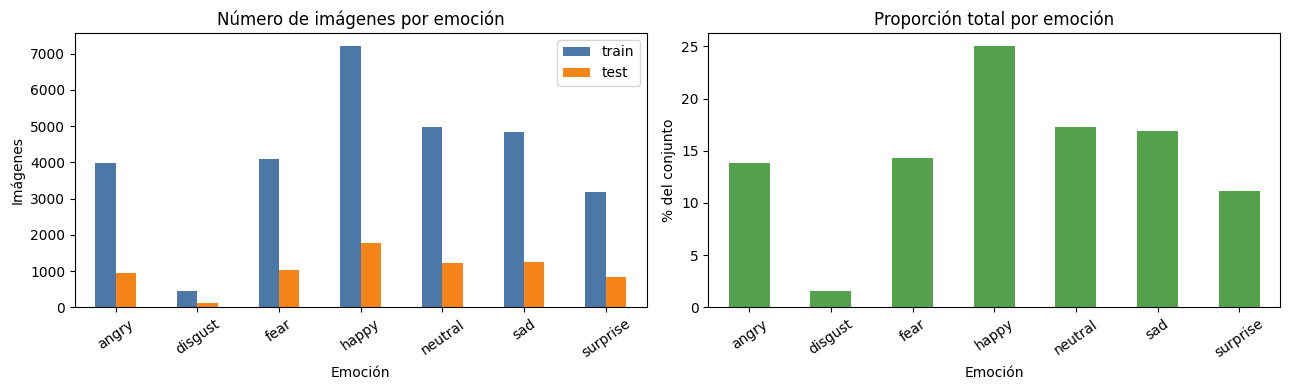

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts[["train", "test"]].plot(
    kind="bar",
    ax=axes[0],
    color=["#4C78A8", "#F58518"]
)
axes[0].set_title("Número de imágenes por emoción")
axes[0].set_xlabel("Emoción")
axes[0].set_ylabel("Imágenes")
axes[0].tick_params(axis="x", rotation=35)

counts["total_%"].plot(
    kind="bar",
    ax=axes[1],
    color="#54A24B"
)
axes[1].set_title("Proporción total por emoción")
axes[1].set_xlabel("Emoción")
axes[1].set_ylabel("% del conjunto")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Para poder analizar bien nuestro dataset, vamos a ver ejemplos reales de cada emoción que tenemos.

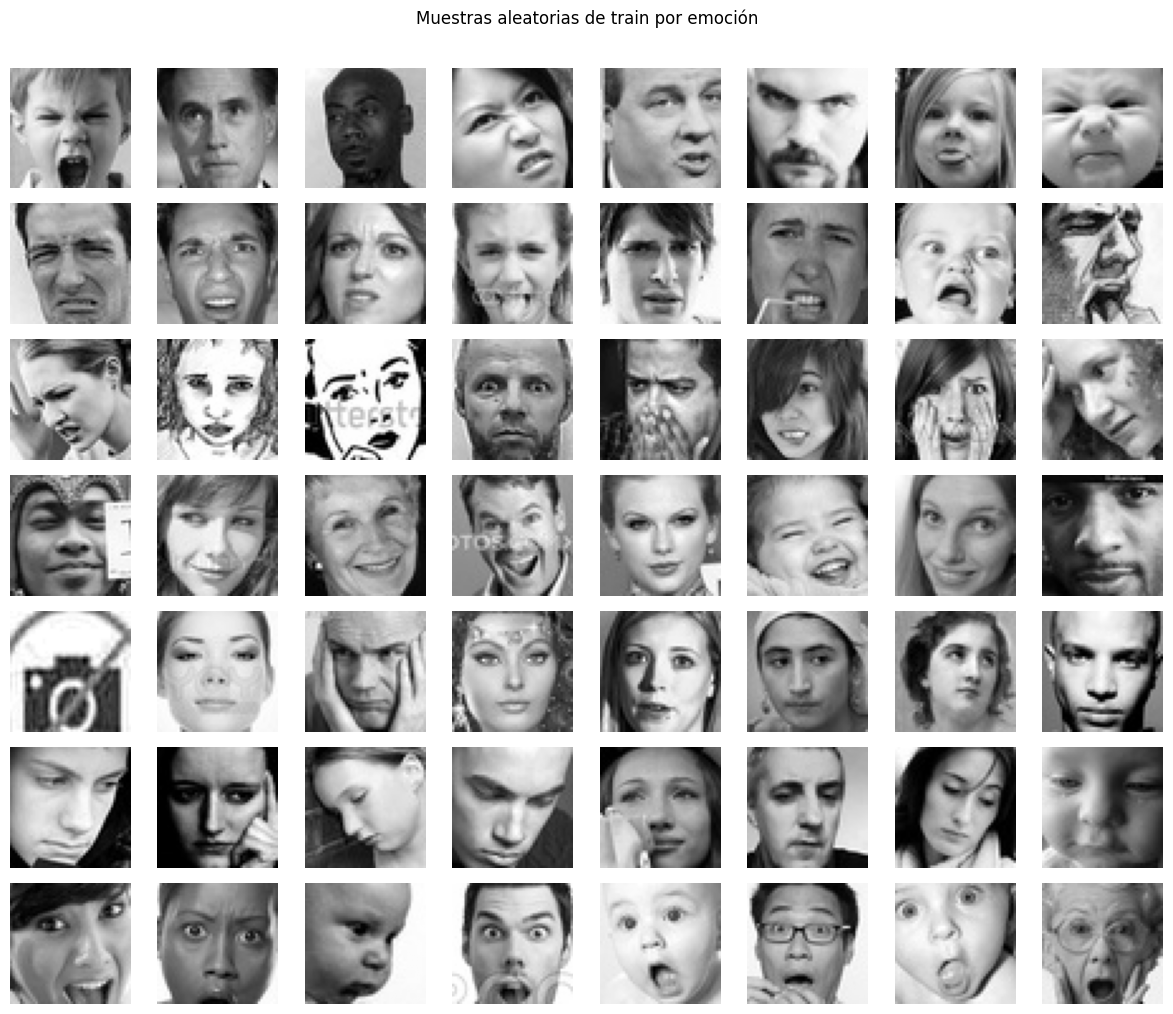

In [7]:
from PIL import Image

rng = np.random.default_rng(42)

fig, axes = plt.subplots(len(CLASSES), 8, figsize=(12, 10))

for row, emotion in enumerate(CLASSES):
    files = list((ROOT / "train" / emotion).glob("*.jpg"))
    selected = rng.choice(files, size=8, replace=False)

    for col, path in enumerate(selected):
        image = Image.open(path).convert("L")
        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        emotion,
        rotation=0,
        labelpad=35,
        va="center"
    )

plt.suptitle("Muestras aleatorias de train por emoción", y=1.01)
plt.tight_layout()
plt.show()

Aquí podemos ver ejemplos de las imágenes que respersetan a cada emoción. Como podemos ver no hace falta que sean imágenes de personas reales. También, la imagen de la quinta fila, en la primera posición, no pertenece a ninguna emocion, es un icono de "foto no disponible". Esto nos da indicios de que puede haber algunas imágenes que no sono rostros. Tendremos que, en el preprocesado, encargarnos de ello.

Comprobamos ahora el formato y tamaño de las imágenes para verificar que sea el esperado:

In [8]:
info = []

for split in ["train", "test"]:
    for emotion in CLASSES:
        files = list((ROOT / split / emotion).glob("*.jpg"))

        for path in files[:20]:
            with Image.open(path) as image:
                info.append({
                    "split": split,
                    "emotion": emotion,
                    "size": image.size,
                    "mode": image.mode
                })

info = pd.DataFrame(info)

display(info["size"].value_counts().rename("n_imágenes"))
display(info["mode"].value_counts().rename("n_imágenes"))

size
(48, 48)    280
Name: n_imágenes, dtype: int64

mode
L    280
Name: n_imágenes, dtype: int64

Como podemos observar, en una muestra de 280 imágenes, se verifica que son de tamaño 48x48, lo que son ligeras para el entrenamiento, y solo tienen un único canal de gris.

Ahora calculamos el brillo y contraste para todas las imágenes de train:

In [9]:
rows = []

for emotion in CLASSES:
    files = list((ROOT / "train" / emotion).glob("*.jpg"))

    for path in files:
        image = np.array(Image.open(path).convert("L"))

        rows.append({
            "emotion": emotion,
            "brightness": image.mean(),
            "contrast": image.std()
        })

pixel_stats = pd.DataFrame(rows)

display(
    pixel_stats.groupby("emotion")[["brightness", "contrast"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

brightness                contrast              
               mean  median    std     mean median    std
emotion                                                  
angry        126.23  127.16  33.17    54.42  53.97  13.71
disgust      135.23  132.70  33.14    52.22  50.23  14.09
fear         135.52  136.89  32.41    54.68  54.20  13.57
happy        129.43  127.92  32.05    53.15  52.60  12.87
neutral      123.90  123.59  33.19    54.29  54.37  14.68
sad          121.28  121.23  33.47    53.75  52.90  14.09
surprise     146.26  148.70  31.69    55.19  55.34  12.86

Podemos ver que surprise es la emoción más clara de media, vemos que el brillo esta a 146. Sad es la menos brillante, con valor 121. Vemos que el contraste entre clases es muy parecido, aproximadamente entre 52-55. Por tanto, el brillo aunque aporta información no es lo suficientemente fuerte como para separar emocionones, ya que hay bastante variabildiad entre clases.

Vamos ahora a visualizar las distribuciones:

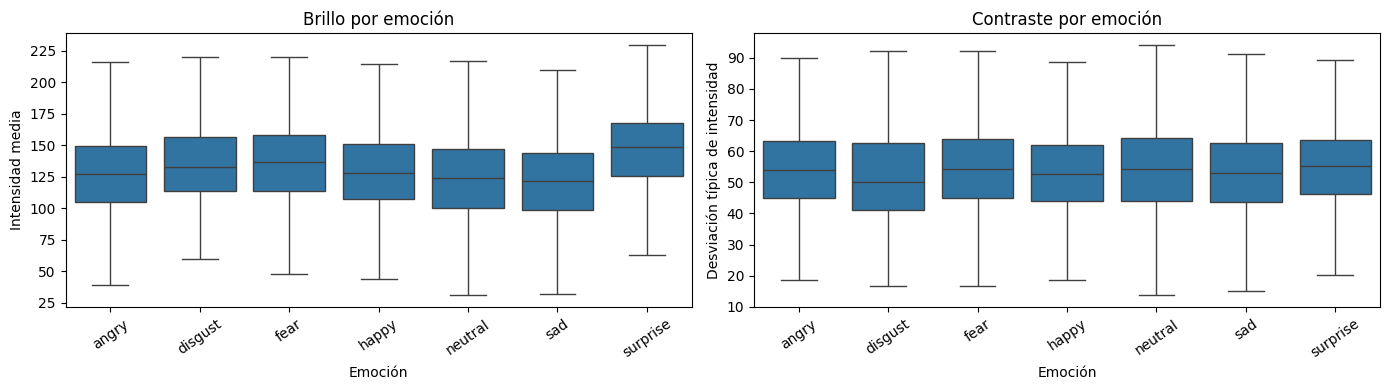

In [11]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(
    data=pixel_stats,
    x="emotion",
    y="brightness",
    order=CLASSES,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Brillo por emoción")
axes[0].set_xlabel("Emoción")
axes[0].set_ylabel("Intensidad media")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(
    data=pixel_stats,
    x="emotion",
    y="contrast",
    order=CLASSES,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Contraste por emoción")
axes[1].set_xlabel("Emoción")
axes[1].set_ylabel("Desviación típica de intensidad")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Volvemos a confirmar que el brillo no varía mucho. De vuelta, confirmamos que apriori no será lo que más ayude para la predicción.

Ahora vamos a definir la función dhash tal y como la definen en el repo original.

In [12]:
from skimage import color, transform, util

def dhash(im, s=8):
    g = color.rgb2gray(im) if im.ndim == 3 else util.img_as_float(im)
    g = transform.resize(g, (s, s + 1), anti_aliasing=True)
    return (g[:, 1:] > g[:, :-1]).ravel()

def dhash_text(im):
    bits = dhash(im)
    return np.packbits(bits).tobytes().hex()

In [13]:
hash_rows = []

for emotion in CLASSES:
    files = list((ROOT / "train" / emotion).glob("*.jpg"))

    for path in files:
        image = np.array(Image.open(path).convert("L"))

        hash_rows.append({
            "path": path,
            "emotion": emotion,
            "dhash": dhash_text(image)
        })

train_hashes = pd.DataFrame(hash_rows)

print("Imágenes procesadas:", len(train_hashes))
print("Hashes dHash distintos:", train_hashes["dhash"].nunique())

Imágenes procesadas: 28709
Hashes dHash distintos: 27367


Creamos una tabla con la ruta, emoción, y huella dHash de cada cara. Podemos ver que si que existen valores hash que son iguales en algunas imágenes.

In [14]:
dhash_groups = (
    train_hashes
    .groupby("dhash")
    .agg(
        n_images=("path", "size"),
        n_emotions=("emotion", "nunique"),
        emotions=("emotion", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

duplicate_groups = dhash_groups[dhash_groups["n_images"] > 1]

print("Grupos dHash repetidos:", len(duplicate_groups))
print("Imágenes dentro de grupos repetidos:",
      duplicate_groups["n_images"].sum())

display(
    duplicate_groups
    .sort_values(["n_emotions", "n_images"], ascending=False)
    .head(15)
)

Grupos dHash repetidos: 1103
Imágenes dentro de grupos repetidos: 2445


,dhash,n_images,n_emotions,emotions
0,0000000000000000,11,5,"angry, happy, neutral, sad, surprise"
22039,f0f0f0f0d4d4f0f0,4,3,"happy, neutral, surprise"
6510,5b9dbedadedccc1c,6,2,"fear, surprise"
25495,f8fcf2f6dcdcfa7f,5,2,"fear, surprise"
418,0301406151301000,4,2,"fear, surprise"
5058,3b39392d2d393939,4,2,"disgust, surprise"
18450,e0f09094848cc4e4,4,2,"disgust, fear"
564,036321191010110d,3,2,"fear, neutral"
2880,23031533070f0f23,3,2,"angry, sad"
5879,4140b0b0c48484e1,3,2,"angry, sad"


Como podemos ver, tenemos un valor hash todo 0s. Esto nos puede indicar que hay imágenes sin nada. Pero vamos a confirmar visualmente que son estas imagenes:

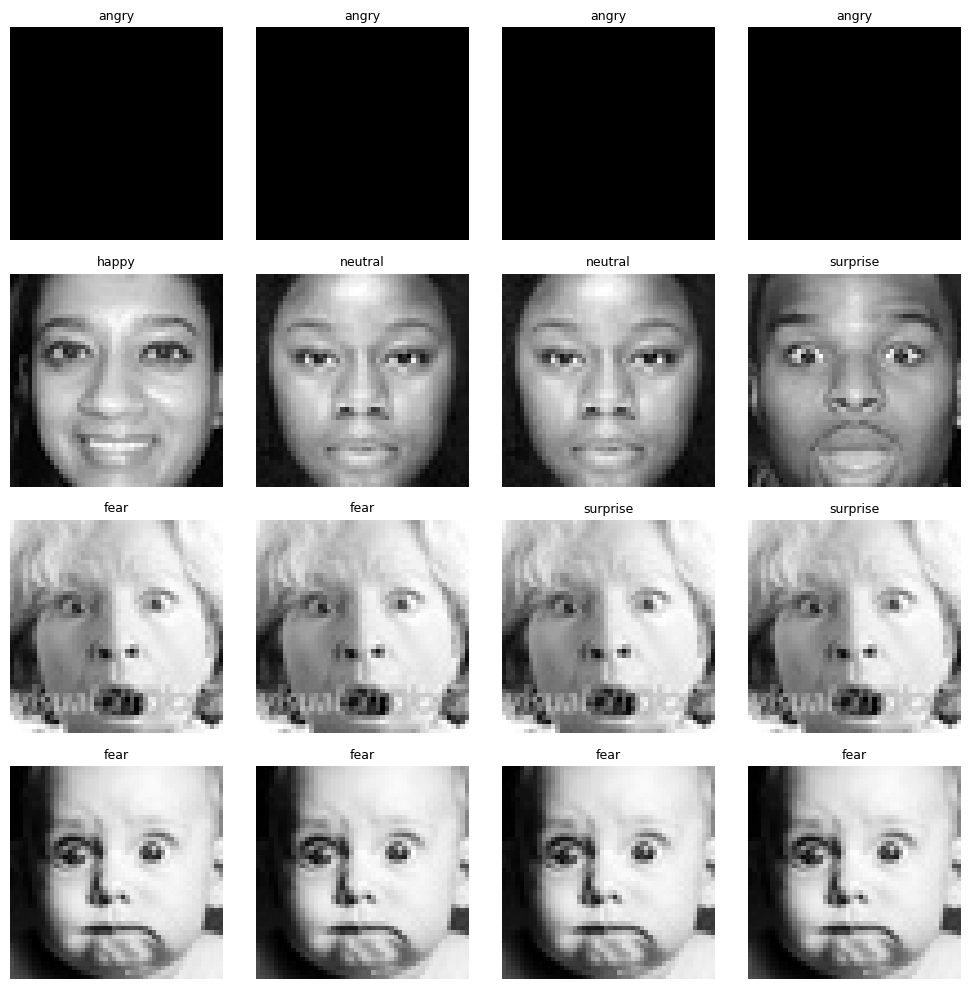

In [15]:
groups_to_show = (
    duplicate_groups
    .sort_values(["n_emotions", "n_images"], ascending=False)
    .head(4)
)

fig, axes = plt.subplots(len(groups_to_show), 4, figsize=(10, 2.5 * len(groups_to_show)))

for row, (_, group) in enumerate(groups_to_show.iterrows()):
    examples = train_hashes[
        train_hashes["dhash"] == group["dhash"]
    ].head(4)

    for col, (_, image_row) in enumerate(examples.iterrows()):
        image = Image.open(image_row["path"]).convert("L")

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(image_row["emotion"], fontsize=9)
        axes[row, col].axis("off")

    for col in range(len(examples), 4):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"n={group['n_images']}\n{group['emotions']}",
        rotation=0,
        labelpad=55,
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

Aquí vemos ejemplos de las imágenes. Efectivamente, tenemos imágenes sin nada. Para estos casos, no solo valdrá con borrar todas las imágenes menos 1, tendremos que borrar todas.

Ahora vamos a calcular que impacto tendría teórico y convservador por emoción.

In [16]:
same_emotion_groups = duplicate_groups[
    duplicate_groups["n_emotions"] == 1
].copy()

same_hashes = set(same_emotion_groups["dhash"])

same_emotion_rows = train_hashes[
    train_hashes["dhash"].isin(same_hashes)
]

dedup_by_emotion = (
    same_emotion_rows
    .groupby("emotion")
    .agg(
        images_in_repeated_groups=("path", "size"),
        groups=("dhash", "nunique")
    )
    .reindex(CLASSES, fill_value=0)
)

dedup_by_emotion["would_remove"] = (
    dedup_by_emotion["images_in_repeated_groups"]
    - dedup_by_emotion["groups"]
)

dedup_by_emotion["train_before"] = counts["train"]
dedup_by_emotion["train_after"] = (
    dedup_by_emotion["train_before"]
    - dedup_by_emotion["would_remove"]
)

dedup_by_emotion["removed_%"] = (
    100 * dedup_by_emotion["would_remove"]
    / dedup_by_emotion["train_before"]
).round(2)

display(dedup_by_emotion)

,images_in_repeated_groups,groups,would_remove,train_before,train_after,removed_%
emotion,,,,,,
angry,266,109,157,3995,3838,3.93
disgust,100,43,57,436,379,13.07
fear,374,175,199,4097,3898,4.86
happy,254,124,130,7215,7085,1.80
neutral,180,86,94,4965,4871,1.89
sad,208,99,109,4830,4721,2.26
surprise,908,409,499,3171,2672,15.74


Vemos que en train habría unas 1245 imágenes a quitar, surprise sería la más afectada, perdiendo un 15.74%. Tenemos que vigilar especialmente a disgust, ya que tiene muy pocos datos ya de inicio. Pierde 13.07% de las imágenes. El resto pierde menos, entre 1.8 y 4.9. Esto haría que el desbalance empeore.

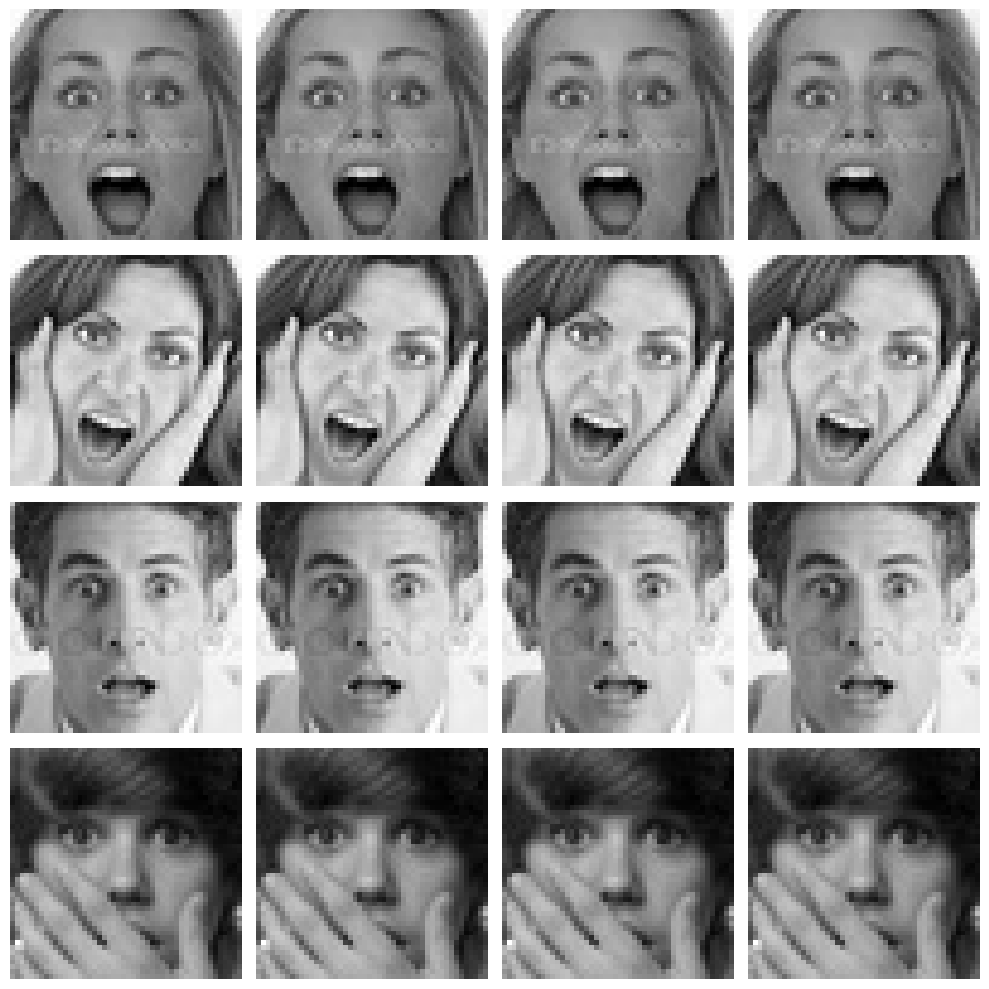

In [17]:
groups_to_review = (
    same_emotion_groups[
        same_emotion_groups["emotions"].isin(["surprise", "disgust"])
    ]
    .sort_values("n_images", ascending=False)
    .head(4)
)

fig, axes = plt.subplots(
    len(groups_to_review), 4,
    figsize=(10, 2.5 * len(groups_to_review))
)

for row, (_, group) in enumerate(groups_to_review.iterrows()):
    images = train_hashes[
        train_hashes["dhash"] == group["dhash"]
    ].head(4)

    for col, (_, image_row) in enumerate(images.iterrows()):
        image = Image.open(image_row["path"]).convert("L")

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

    for col in range(len(images), 4):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"{group['emotions']}\nn={group['n_images']}",
        rotation=0,
        labelpad=35,
        va="center"
    )

plt.tight_layout()
plt.show()

Vemos que los duplicados son razonables. Es importante ver esto ya que dhash no siempre que da el mismo hash da a idénticos, sino a muy parecidos. También confirmamos que no ocurre una colisión.

Repetimos dhash en test:

In [18]:
hash_rows = []

for emotion in CLASSES:
    files = list((ROOT / "test" / emotion).glob("*.jpg"))

    for path in files:
        image = np.array(Image.open(path).convert("L"))

        hash_rows.append({
            "path": path,
            "emotion": emotion,
            "dhash": dhash_text(image)
        })

test_hashes = pd.DataFrame(hash_rows)

print("Imágenes procesadas en test:", len(test_hashes))
print("Hashes dHash distintos:", test_hashes["dhash"].nunique())

Imágenes procesadas en test: 7178
Hashes dHash distintos: 7075


Podemos ver que en test se pierden 103 imágenes por el hash.

In [19]:
shared_hashes = set(train_hashes["dhash"]) & set(test_hashes["dhash"])

train_shared = train_hashes[
    train_hashes["dhash"].isin(shared_hashes)
]

test_shared = test_hashes[
    test_hashes["dhash"].isin(shared_hashes)
]

print("Hashes dHash compartidos entre train y test:", len(shared_hashes))
print("Imágenes de train implicadas:", len(train_shared))
print("Imágenes de test implicadas:", len(test_shared))

shared_summary = (
    pd.concat([
        train_shared.assign(split="train"),
        test_shared.assign(split="test")
    ])
    .groupby("dhash")
    .agg(
        emociones=("emotion", lambda x: ", ".join(sorted(set(x)))),
        imágenes_train=("split", lambda x: (x == "train").sum()),
        imágenes_test=("split", lambda x: (x == "test").sum())
    )
    .reset_index()
)

display(shared_summary.head(15))

Hashes dHash compartidos entre train y test: 581
Imágenes de train implicadas: 792
Imágenes de test implicadas: 624


,dhash,emociones,imágenes_train,imágenes_test
0,0000000000000000,"angry, happy, neutral, sad, surprise",11,1
1,0000103616120623,sad,1,1
2,0060d0d4c4844441,happy,1,1
3,0121131304070f8f,surprise,1,1
4,0121644a1d191195,neutral,1,1
5,0131705244644c6d,surprise,1,1
6,0301000030181818,fear,1,1
7,035151544d4d0d68,surprise,2,1
8,036110332707050b,sad,1,1
9,0701222626260e06,fear,1,1


Aquí podemos ver la correspondencia de los duplicados que se comparten en train y test.

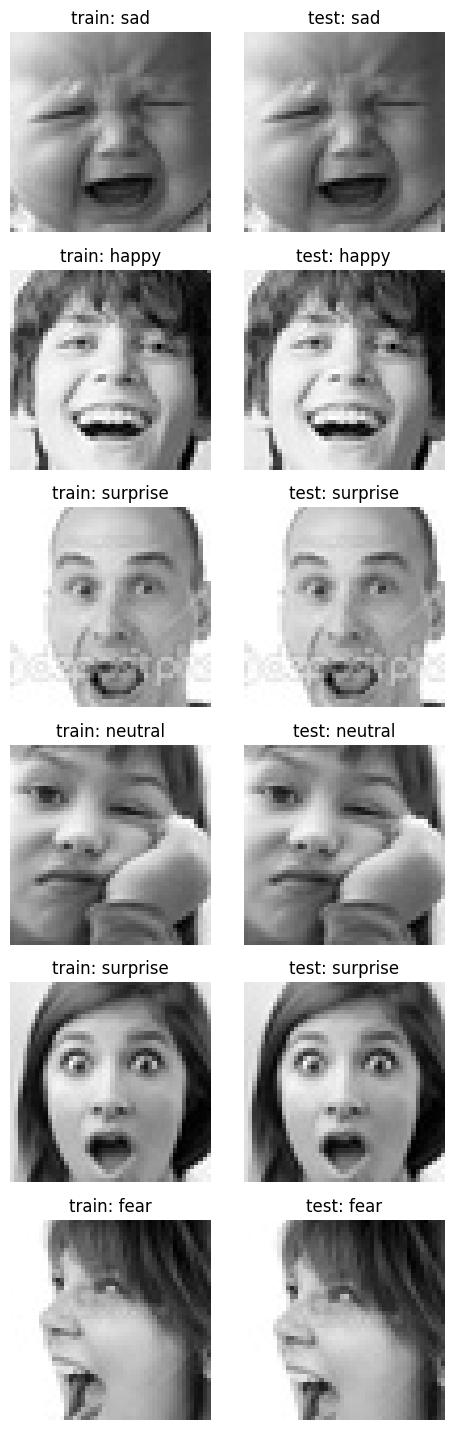

In [20]:
hashes_to_review = (
    shared_summary[
        shared_summary["dhash"] != "0000000000000000"
    ]
    .head(6)["dhash"]
    .tolist()
)

fig, axes = plt.subplots(len(hashes_to_review), 2, figsize=(5, 2.4 * len(hashes_to_review)))

for row, hash_value in enumerate(hashes_to_review):
    for col, (split, table) in enumerate([
        ("train", train_hashes),
        ("test", test_hashes)
    ]):
        image_row = table[table["dhash"] == hash_value].iloc[0]
        image = Image.open(image_row["path"]).convert("L")

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(f"{split}: {image_row['emotion']}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

Revisamos que estas imágenes tienen las mismas caras, por lo que hay una posible fuga de datos.

In [21]:
valid_shared_hashes = [
    h for h in shared_hashes
    if h != "0000000000000000"
]

cross_split_pairs = (
    train_hashes[train_hashes["dhash"].isin(valid_shared_hashes)]
    .merge(
        test_hashes[test_hashes["dhash"].isin(valid_shared_hashes)],
        on="dhash",
        suffixes=("_train", "_test")
    )
)

cross_split_pairs["same_emotion"] = (
    cross_split_pairs["emotion_train"]
    == cross_split_pairs["emotion_test"]
)

print("Pares train-test candidatos:", len(cross_split_pairs))
print("Con la misma etiqueta:", cross_split_pairs["same_emotion"].sum())
print("Con etiquetas distintas:", (~cross_split_pairs["same_emotion"]).sum())

display(
    cross_split_pairs
    .groupby(["emotion_train", "emotion_test"])
    .size()
    .rename("n_pares")
    .reset_index()
    .sort_values("n_pares", ascending=False)
)

Pares train-test candidatos: 876
Con la misma etiqueta: 815
Con etiquetas distintas: 61


,emotion_train,emotion_test,n_pares
22,surprise,surprise,324
0,angry,angry,144
7,fear,fear,129
10,happy,happy,57
19,sad,sad,55
14,neutral,neutral,54
5,disgust,disgust,52
8,fear,sad,11
9,fear,surprise,9
2,angry,fear,8


Aquí anteriormente vemos los pares con el msimo hash. Algunos llegan a tener etiquetas distintas. 

### Preprocesado de los datos

Lo primero que haremos descartar todas las imágenes que tengan el hash 00000000, y en el caso de los demás hashes, nos quedamos solo con 1. Si la imagen está en test, se prioriza la de test para que no se deje la copia equivalente en train y evitar una fuga de datos.